In [1]:
from fxml import config
from fxml.datasets.scaling import FeatureScaler
from fxml.db.connection import connect
from fxml.db.repository import load_bars
from fxml.evaluation import plots
from fxml.features.builder import CYCLICAL_COLUMNS, FEATURE_COLUMNS, build_features
from fxml.labels.targets import forward_return

plots.apply_style()
bars = load_bars(connect(), "EURUSD", "H1", start=config.TRAIN_START)
features = build_features(bars)
target = forward_return(bars["close"], config.LABEL_HORIZON)
data = features.join(target.rename("target")).dropna()

# exploration only: fit the scaler on the first 70% of rows
split = int(len(data) * 0.7)
scaler = FeatureScaler(passthrough=CYCLICAL_COLUMNS).fit(data[FEATURE_COLUMNS].iloc[:split])
scaled = scaler.transform(data[FEATURE_COLUMNS])
print(len(data), "rows from", data.index.min(), "to", data.index.max())


73347 rows from 2015-01-05 07:00:00+00:00 to 2026-10-16 15:00:00+00:00


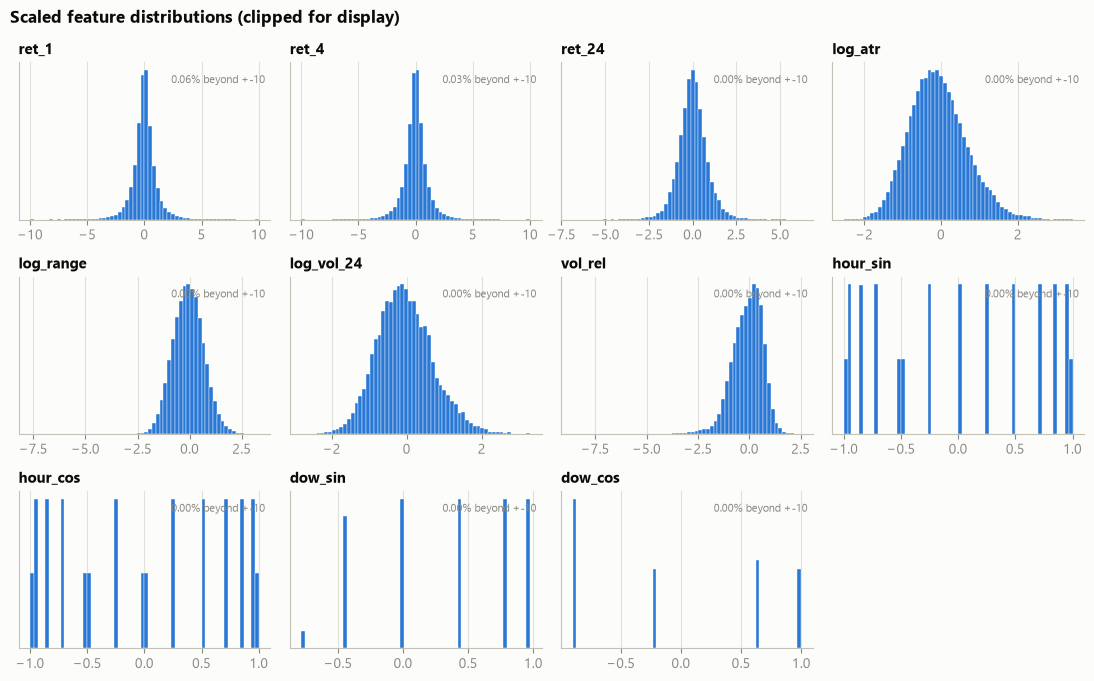

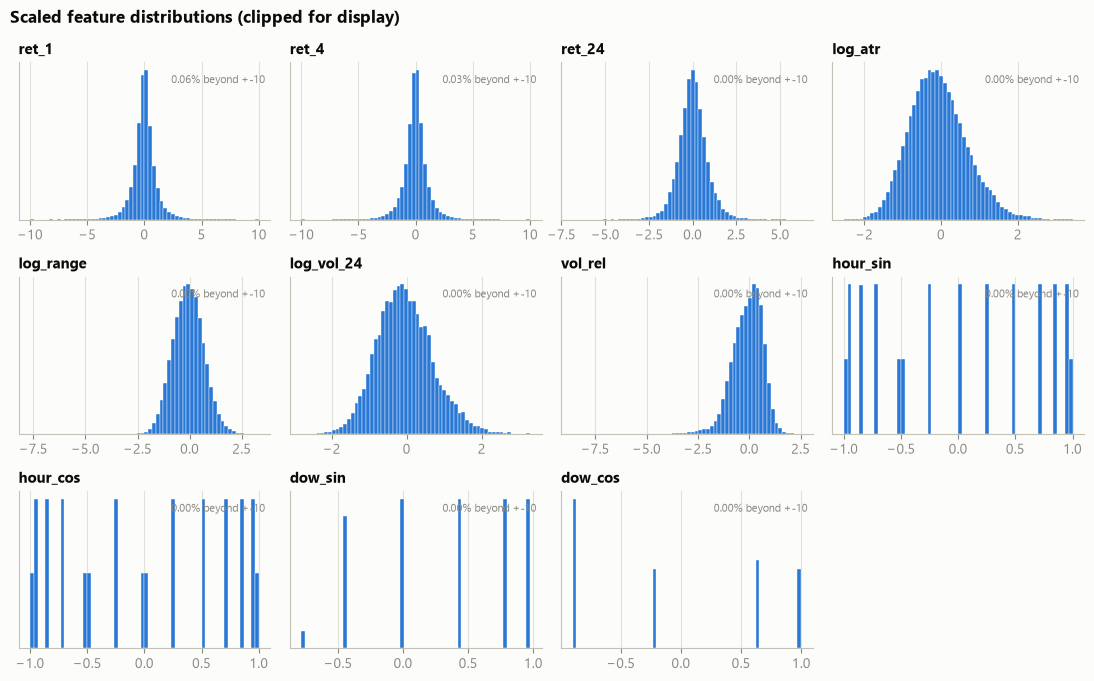

In [2]:
plots.feature_distributions(scaled)


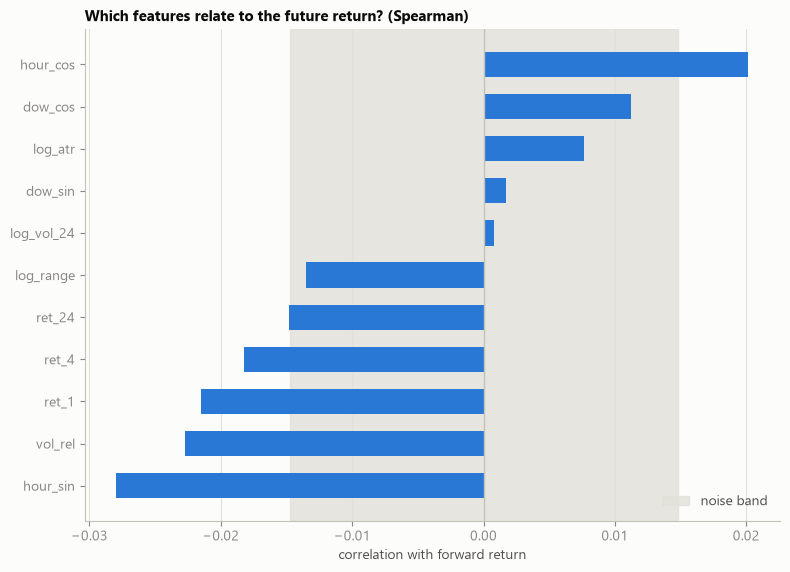

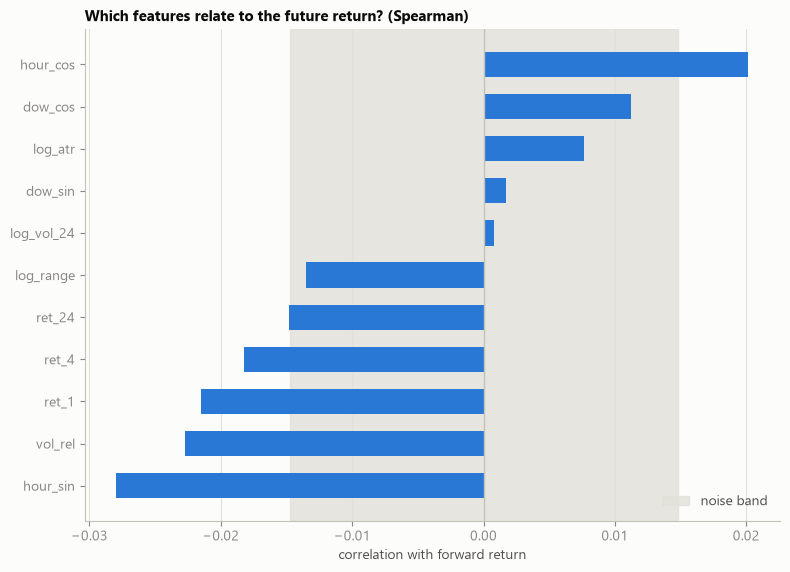

In [3]:
plots.feature_target_correlation(data[FEATURE_COLUMNS], data["target"], config.LABEL_HORIZON)


In [4]:
up_share = (data["target"] > 0).mean()
print(f"Share of up moves:              {up_share:.3f}")
print(f"Accuracy of always guessing the majority: {max(up_share, 1 - up_share):.3f}")
print(f"RMSE of predicting zero return: {(data['target'] ** 2).mean() ** 0.5:.5f}")


Share of up moves:              0.501
Accuracy of always guessing the majority: 0.501
RMSE of predicting zero return: 0.00203


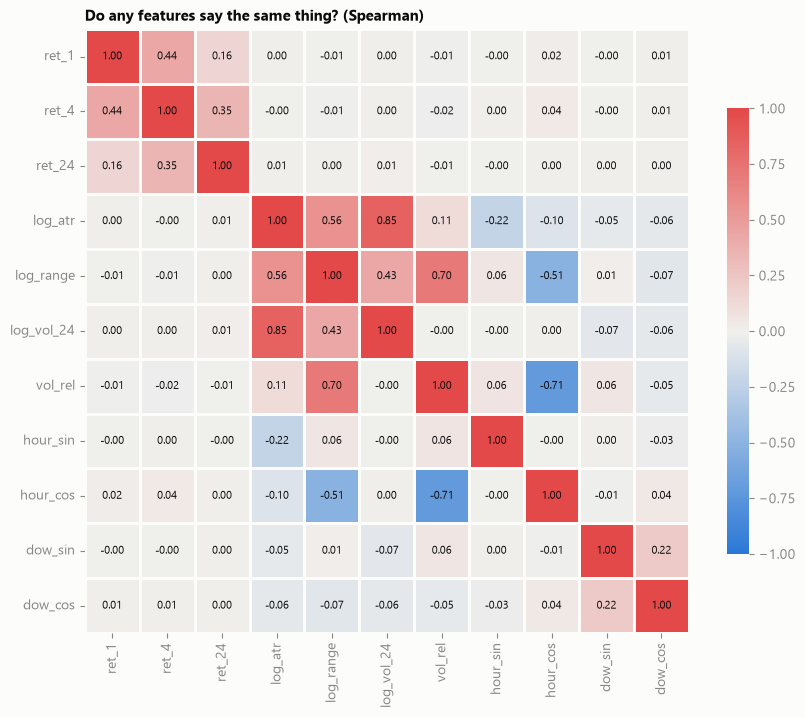

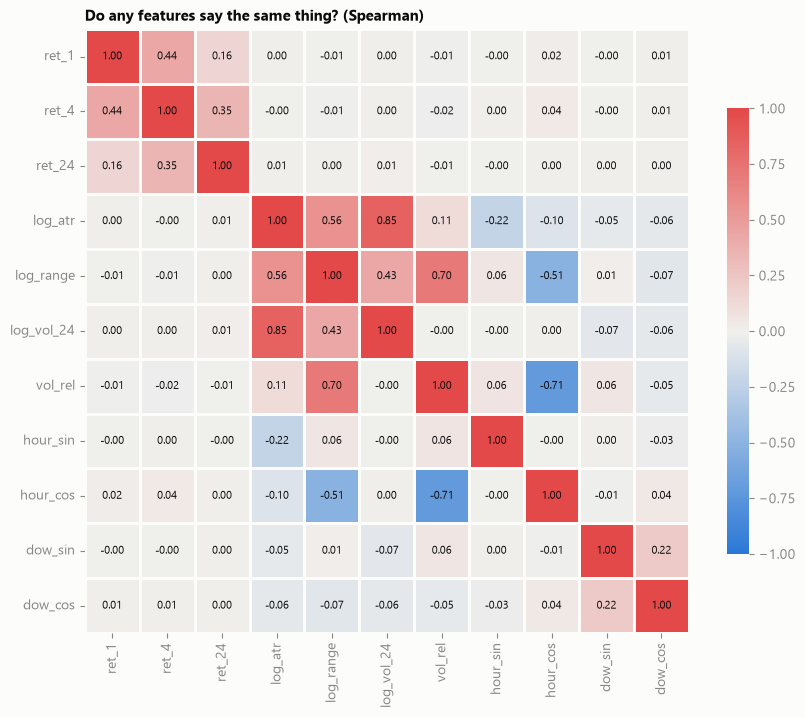

In [5]:
plots.feature_correlation_heatmap(data[FEATURE_COLUMNS])
